# 1. DATA UNDERSTANDING

## 1.1. Import Library & Konfigurasi Global Dataset

In [4]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Konfigurasi visualisasi & reproducibility
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

print("Library berhasil dimuat. RANDOM_STATE =", RANDOM_STATE)

Library berhasil dimuat. RANDOM_STATE = 42


## 1.2. Data Loading & Integrasi Relasional ke Level order_id.

In [13]:
possible_paths = [
    '/kaggle/input/brazilian-ecommerce/',
    './dataset/',
    './'
]
DATA_DIR = next((p for p in possible_paths if os.path.exists(os.path.join(p, 'olist_orders_dataset.csv'))), None)

if DATA_DIR is None:
    raise FileNotFoundError("Dataset Olist tidak ditemukan. Pastikan file CSV berada di '/kaggle/input/brazilian-ecommerce/' atau './data/'.")

print(f"Memuat dataset dari direktori: {DATA_DIR}")

orders = pd.read_csv(os.path.join(DATA_DIR, 'olist_orders_dataset.csv'))
reviews = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_reviews_dataset.csv'))
items = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_items_dataset.csv'))
payments = pd.read_csv(os.path.join(DATA_DIR, 'olist_order_payments_dataset.csv'))
customers = pd.read_csv(os.path.join(DATA_DIR, 'olist_customers_dataset.csv'))
sellers = pd.read_csv(os.path.join(DATA_DIR, 'olist_sellers_dataset.csv'))
products = pd.read_csv(os.path.join(DATA_DIR, 'olist_products_dataset.csv'))
geo = pd.read_csv(os.path.join(DATA_DIR, 'olist_geolocation_dataset.csv'))
cat_trans = pd.read_csv(os.path.join(DATA_DIR, 'product_category_name_translation.csv'))

datasets_info = {
    'orders': orders, 'reviews': reviews, 'items': items,
    'payments': payments, 'customers': customers, 'sellers': sellers,
    'products': products, 'geolocation': geo, 'category_translation': cat_trans
}

for name, df_temp in datasets_info.items():
    print(f"- {name:22s}: {df_temp.shape[0]:9,d} baris | {df_temp.shape[1]:2d} kolom")

Memuat dataset dari direktori: ./dataset/
- orders                :    99,441 baris |  8 kolom
- reviews               :    99,224 baris |  7 kolom
- items                 :   112,650 baris |  7 kolom
- payments              :   103,886 baris |  5 kolom
- customers             :    99,441 baris |  5 kolom
- sellers               :     3,095 baris |  4 kolom
- products              :    32,951 baris |  9 kolom
- geolocation           : 1,000,163 baris |  5 kolom
- category_translation  :        71 baris |  2 kolom


## 1.3. Audit Kualitas Data (Missinv Values, Duplicate, Outlier)

In [ ]:
def audit_dataframe(df, name):
    print(f"\n{'='*70}")
    print(f"AUDIT KUALITAS DATA: {name.upper()} (Total Baris: {len(df):,d})")
    print(f"{'='*70}")
    
    # 1. Cek Duplikasi Baris Penuh & Primary/Foreign Key
    exact_dup = df.duplicated().sum()
    print(f"Duplikasi baris penuh : {exact_dup:,d}")
    if 'order_id' in df.columns:
        order_dup = df['order_id'].duplicated().sum()
        print(f"Duplikasi order_id    : {order_dup:,d}")
        
    # 2. Ringkasan Missing Values & Tipe Data
    audit_tbl = pd.DataFrame({
        'Tipe_Data': df.dtypes,
        'Missing_Count': df.isnull().sum(),
        'Missing_Pct (%)': (df.isnull().sum() / len(df)) * 100,
        'Unique_Values': df.nunique()
    })
    print("\n--- Ringkasan Missing Value & Kardinalitas ---")
    print(audit_tbl[audit_tbl['Missing_Count'] > 0].sort_values(by='Missing_Pct (%)', ascending=False))
    if (audit_tbl['Missing_Count'] == 0).all():
        print("Tidak ada missing value pada tabel ini.")

    # 3. Deteksi Outlier pada Kolom Numerik menggunakan Metode IQR
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    num_cols = [c for c in num_cols if not c.endswith('_prefix') and c != 'review_score']
    if num_cols:
        outlier_rows = []
        for col in num_cols:
            series = df[col].dropna()
            Q1 = series.quantile(0.25)
            Q3 = series.quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - 1.5 * IQR
            upper = Q3 + 1.5 * IQR
            outliers = ((series < lower) | (series > upper)).sum()
            outlier_rows.append({
                'Kolom': col,
                'Q1': round(Q1, 2),
                'Median': round(series.median(), 2),
                'Q3': round(Q3, 2),
                'Outlier_IQR_Count': outliers,
                'Outlier_Pct (%)': round((outliers / len(series)) * 100, 2)
            })
        print("\n--- Deteksi Outlier Numerik (Metode IQR 1.5x) ---")
        print(pd.DataFrame(outlier_rows).to_string(index=False))

for tbl_name in ['orders', 'reviews', 'items', 'payments', 'products']:
    audit_dataframe(datasets_info[tbl_name], tbl_name)


AUDIT KUALITAS DATA: ORDERS (Total Baris: 99,441)
Duplikasi baris penuh : 0
Duplikasi order_id    : 0

--- Ringkasan Missing Value & Kardinalitas ---
                              Tipe_Data  Missing_Count  Missing_Pct (%)  \
order_delivered_customer_date    object           2965           2.9817   
order_delivered_carrier_date     object           1783           1.7930   
order_approved_at                object            160           0.1609   

                               Unique_Values  
order_delivered_customer_date          95664  
order_delivered_carrier_date           81018  
order_approved_at                      90733  

AUDIT KUALITAS DATA: REVIEWS (Total Baris: 99,224)
Duplikasi baris penuh : 0
Duplikasi order_id    : 551

--- Ringkasan Missing Value & Kardinalitas ---
                       Tipe_Data  Missing_Count  Missing_Pct (%)  \
review_comment_title      object          87656          88.3415   
review_comment_message    object          58247          58.7025   

 

## 1.4. Merge Data untuk EDA & Statistik Deskriptif

In [ ]:
# 1. Konversi kolom timestamp pada orders & reviews
date_cols_orders = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols_orders:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

reviews['review_creation_date'] = pd.to_datetime(reviews['review_creation_date'], errors='coerce')
reviews['review_answer_timestamp'] = pd.to_datetime(reviews['review_answer_timestamp'], errors='coerce')

# 2. Agregasi tabel 1-to-many ke level order_id agar tidak terjadi duplikasi
# Reviews: ambil ulasan terakhir/terbaru per order_id
reviews_agg = (
    reviews.sort_values('review_creation_date')
    .groupby('order_id', as_index=False)
    .last()
)

# Products + translation
products_clean = products.merge(cat_trans, on='product_category_name', how='left')
products_clean['product_category_name_english'] = products_clean['product_category_name_english'].fillna(
    products_clean['product_category_name']
)

# Gabungkan items dengan products dan sellers untuk agregasi per order_id
items_enriched = (
    items.merge(products_clean[['product_id', 'product_category_name_english', 'product_weight_g',
                                'product_length_cm', 'product_height_cm', 'product_width_cm']],
                on='product_id', how='left')
         .merge(sellers[['seller_id', 'seller_zip_code_prefix', 'seller_state']],
                on='seller_id', how='left')
)

items_agg = items_enriched.groupby('order_id', as_index=False).agg(
    total_items=('order_item_id', 'count'),
    unique_sellers=('seller_id', 'nunique'),
    total_price=('price', 'sum'),
    total_freight=('freight_value', 'sum'),
    avg_product_weight_g=('product_weight_g', 'mean'),
    main_category=('product_category_name_english', 'first'),
    seller_state=('seller_state', 'first'),
    seller_zip_code_prefix=('seller_zip_code_prefix', 'first'),
    shipping_limit_date=('shipping_limit_date', 'min')
)
items_agg['shipping_limit_date'] = pd.to_datetime(items_agg['shipping_limit_date'], errors='coerce')

# Payments agregasi per order_id
payments_agg = payments.groupby('order_id', as_index=False).agg(
    total_payment_value=('payment_value', 'sum'),
    max_installments=('payment_installments', 'max'),
    payment_methods_count=('payment_sequential', 'max'),
    primary_payment_type=('payment_type', 'first')
)

# Geolocation median lat/lng per zip_code_prefix
geo_agg = geo.groupby('geolocation_zip_code_prefix', as_index=False).agg(
    lat=('geolocation_lat', 'median'),
    lng=('geolocation_lng', 'median')
)

# Merge utama ke level order_id
df_eda = (
    orders.merge(reviews_agg, on='order_id', how='inner')
          .merge(items_agg, on='order_id', how='inner')
          .merge(payments_agg, on='order_id', how='left')
          .merge(customers[['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_state']],
                 on='customer_id', how='left')
)

# Tambahkan koordinat customer & seller untuk menghitung jarak Haversine
df_eda = df_eda.merge(
    geo_agg.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix',
                            'lat': 'cust_lat', 'lng': 'cust_lng'}),
    on='customer_zip_code_prefix', how='left'
).merge(
    geo_agg.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix',
                            'lat': 'sell_lat', 'lng': 'sell_lng'}),
    on='seller_zip_code_prefix', how='left'
)

# Ekstraksi fitur awal untuk EDA
df_eda['is_dissatisfied'] = (df_eda['review_score'] <= 3).astype(int)
df_eda['actual_delivery_days'] = (
    df_eda['order_delivered_customer_date'] - df_eda['order_purchase_timestamp']
).dt.total_seconds() / 86400.0
df_eda['estimated_delivery_days'] = (
    df_eda['order_estimated_delivery_date'] - df_eda['order_purchase_timestamp']
).dt.total_seconds() / 86400.0
df_eda['delivery_diff_days'] = (
    df_eda['order_delivered_customer_date'] - df_eda['order_estimated_delivery_date']
).dt.total_seconds() / 86400.0
df_eda['is_late'] = (df_eda['delivery_diff_days'] > 0).astype(int)
df_eda['freight_ratio'] = df_eda['total_freight'] / (df_eda['total_price'] + 1e-5)
df_eda['has_comment'] = df_eda['review_comment_message'].notnull().astype(int)
df_eda['comment_length'] = df_eda['review_comment_message'].fillna('').str.len()

# Statistik Deskriptif Fitur Utama
eda_num_cols = [
    'review_score', 'actual_delivery_days', 'estimated_delivery_days',
    'delivery_diff_days', 'total_price', 'total_freight', 'freight_ratio',
    'total_items', 'comment_length'
]
desc_stats = df_eda[eda_num_cols].describe().T
desc_stats['skewness'] = df_eda[eda_num_cols].skew()
print("=== STATISTIK DESKRIPTIF VARIABEL UTAMA (EDA) ===")
print(desc_stats[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max', 'skewness']])

=== STATISTIK DESKRIPTIF VARIABEL UTAMA (EDA) ===
                              count     mean      std       min      25%  \
review_score            97,917.0000   4.1045   1.3317    1.0000   4.0000   
actual_delivery_days    95,830.0000  12.5173   9.4609    0.5334   6.7579   
estimated_delivery_days 97,917.0000  23.7669   8.8288    2.0080  18.3341   
delivery_diff_days      95,830.0000 -11.2162  10.1159 -146.0161 -16.2502   
total_price             97,917.0000 137.5343 209.4826    0.8500  45.9000   
total_freight           97,917.0000  22.8040  21.6210    0.0000  13.8400   
freight_ratio           97,917.0000   0.3084   0.3149    0.0000   0.1319   
total_items             97,917.0000   1.1408   0.5338    1.0000   1.0000   
comment_length          97,917.0000  28.0941  48.0829    0.0000   0.0000   

                             50%      75%         max  skewness  
review_score              5.0000   5.0000      5.0000   -1.3949  
actual_delivery_days     10.2062  15.6641    208.3518    

## 1.5. Visualisasi EDA

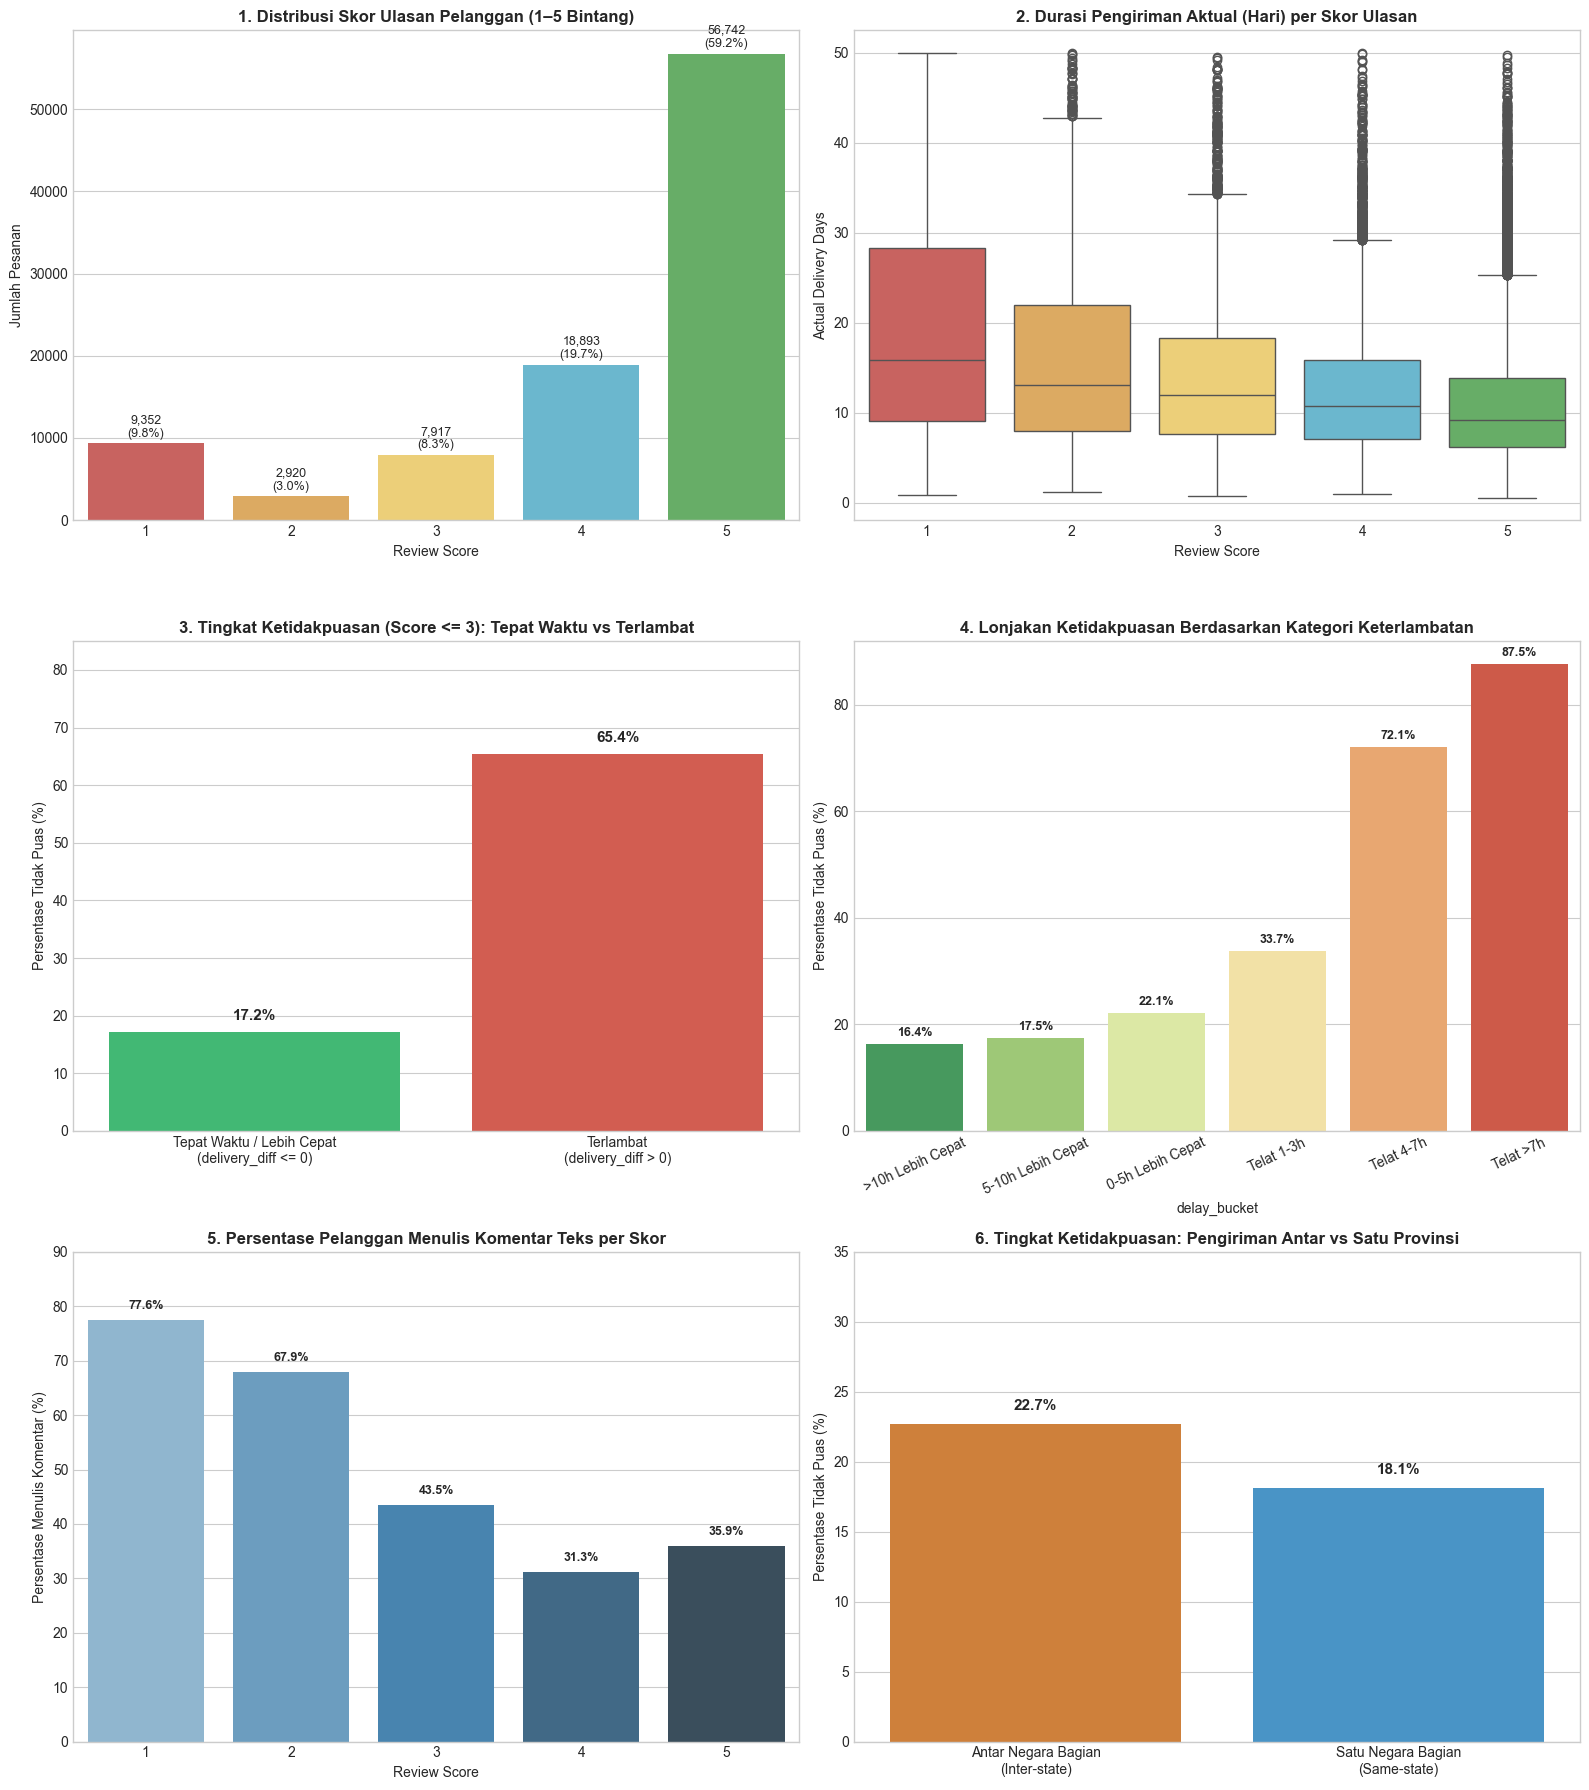

In [ ]:
df_delivered_eda = df_eda[df_eda['order_status'] == 'delivered'].dropna(subset=['actual_delivery_days']).copy()

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# Plot 1: Distribusi Review Score (1-5) & Proporsi Target Biner
score_counts = df_delivered_eda['review_score'].value_counts().sort_index()
colors_score = ['#d9534f', '#f0ad4e', '#ffd966', '#5bc0de', '#5cb85c']
sns.barplot(x=score_counts.index, y=score_counts.values, palette=colors_score, ax=axes[0, 0])
axes[0, 0].set_title('1. Distribusi Skor Ulasan Pelanggan (1–5 Bintang)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Review Score')
axes[0, 0].set_ylabel('Jumlah Pesanan')
for i, v in enumerate(score_counts.values):
    pct = v / len(df_delivered_eda) * 100
    axes[0, 0].text(i, v + 800, f'{v:,}\n({pct:.1f}%)', ha='center', fontsize=9)

# Plot 2: Lama Pengiriman Aktual per Review Score (Boxplot tanpa outlier ekstrem agar terbaca)
sns.boxplot(
    data=df_delivered_eda[df_delivered_eda['actual_delivery_days'] <= 50],
    x='review_score', y='actual_delivery_days', palette=colors_score, ax=axes[0, 1]
)
axes[0, 1].set_title('2. Durasi Pengiriman Aktual (Hari) per Skor Ulasan', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Review Score')
axes[0, 1].set_ylabel('Actual Delivery Days')

# Plot 3: Tingkat Ketidakpuasan Berdasarkan Status Keterlambatan (On-Time vs Late)
late_rate = df_delivered_eda.groupby('is_late')['is_dissatisfied'].mean() * 100
sns.barplot(x=['Tepat Waktu / Lebih Cepat\n(delivery_diff <= 0)', 'Terlambat\n(delivery_diff > 0)'],
            y=late_rate.values, palette=['#2ecc71', '#e74c3c'], ax=axes[1, 0])
axes[1, 0].set_title('3. Tingkat Ketidakpuasan (Score <= 3): Tepat Waktu vs Terlambat', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Persentase Tidak Puas (%)')
axes[1, 0].set_ylim(0, 85)
for i, v in enumerate(late_rate.values):
    axes[1, 0].text(i, v + 2, f'{v:.1f}%', ha='center', fontweight='bold', fontsize=11)

# Plot 4: Tingkat Ketidakpuasan Berdasarkan Besaran Hari Keterlambatan (Binning)
bins = [-100, -10, -5, 0, 3, 7, 200]
labels = ['>10h Lebih Cepat', '5-10h Lebih Cepat', '0-5h Lebih Cepat',
          'Telat 1-3h', 'Telat 4-7h', 'Telat >7h']
df_delivered_eda['delay_bucket'] = pd.cut(df_delivered_eda['delivery_diff_days'], bins=bins, labels=labels)
bucket_dissat = df_delivered_eda.groupby('delay_bucket', observed=False)['is_dissatisfied'].mean() * 100
sns.barplot(x=bucket_dissat.index, y=bucket_dissat.values, palette='RdYlGn_r', ax=axes[1, 1])
axes[1, 1].set_title('4. Lonjakan Ketidakpuasan Berdasarkan Kategori Keterlambatan', fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel('Persentase Tidak Puas (%)')
axes[1, 1].tick_params(axis='x', rotation=25)
for i, v in enumerate(bucket_dissat.values):
    axes[1, 1].text(i, v + 1.5, f'{v:.1f}%', ha='center', fontsize=9, fontweight='bold')

# Plot 5: Proporsi Keberadaan Komentar Teks & Panjang Komentar per Review Score
comment_rate = df_delivered_eda.groupby('review_score')['has_comment'].mean() * 100
sns.barplot(x=comment_rate.index, y=comment_rate.values, palette='Blues_d', ax=axes[2, 0])
axes[2, 0].set_title('5. Persentase Pelanggan Menulis Komentar Teks per Skor', fontsize=12, fontweight='bold')
axes[2, 0].set_xlabel('Review Score')
axes[2, 0].set_ylabel('Persentase Menulis Komentar (%)')
axes[2, 0].set_ylim(0, 90)
for i, v in enumerate(comment_rate.values):
    axes[2, 0].text(i, v + 2, f'{v:.1f}%', ha='center', fontsize=9, fontweight='bold')

# Plot 6: Pengiriman Antar Negara Bagian (Inter-state) vs Dalam Negara Bagian (Same-state)
df_delivered_eda['same_state'] = (df_delivered_eda['customer_state'] == df_delivered_eda['seller_state']).astype(int)
state_dissat = df_delivered_eda.groupby('same_state')['is_dissatisfied'].mean() * 100
sns.barplot(x=['Antar Negara Bagian\n(Inter-state)', 'Satu Negara Bagian\n(Same-state)'],
            y=state_dissat.values, palette=['#e67e22', '#3498db'], ax=axes[2, 1])
axes[2, 1].set_title('6. Tingkat Ketidakpuasan: Pengiriman Antar vs Satu Provinsi', fontsize=12, fontweight='bold')
axes[2, 1].set_ylabel('Persentase Tidak Puas (%)')
axes[2, 1].set_ylim(0, 35)
for i, v in enumerate(state_dissat.values):
    axes[2, 1].text(i, v + 1, f'{v:.1f}%', ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

## 1.6. Analisis Korelasi Antarfitur & Target

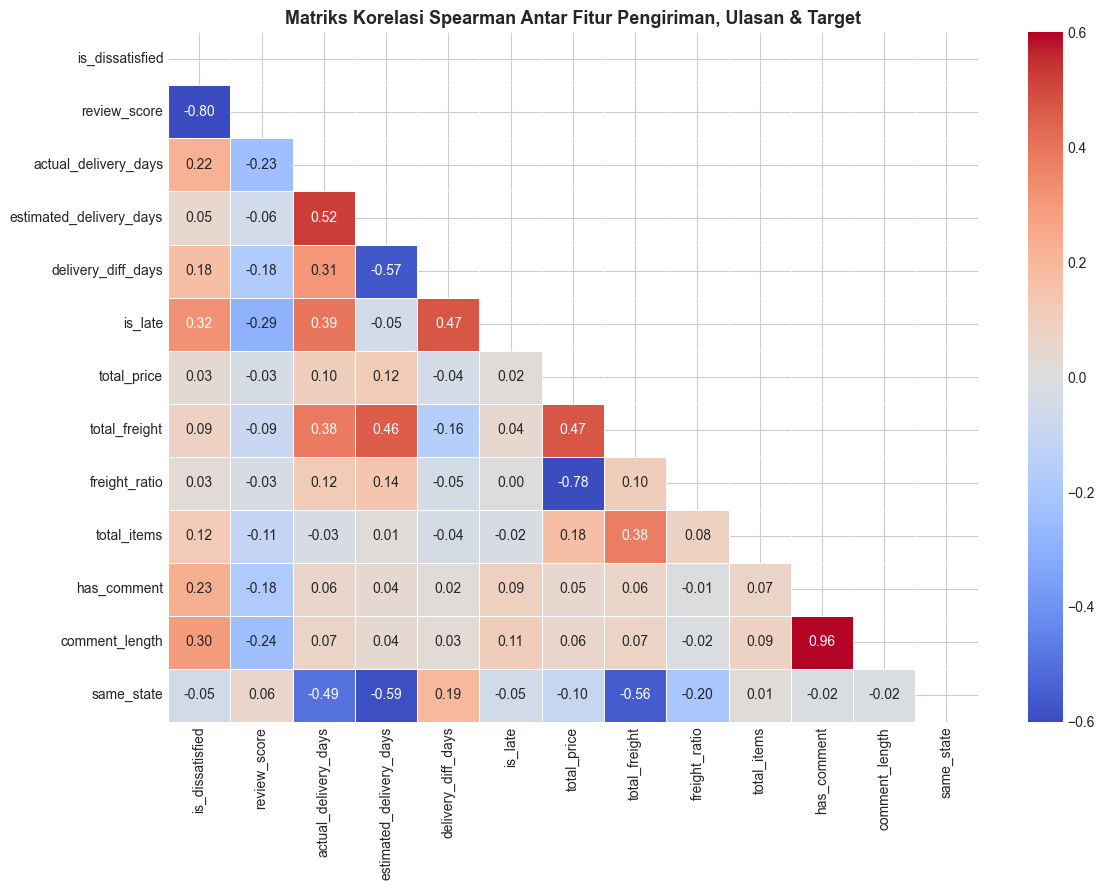

=== KORELASI SPEARMAN TERHADAP TARGET (is_dissatisfied) ===
is_dissatisfied            1.0000
is_late                    0.3207
comment_length             0.2950
has_comment                0.2328
actual_delivery_days       0.2214
delivery_diff_days         0.1771
total_items                0.1244
total_freight              0.0887
estimated_delivery_days    0.0478
total_price                0.0341
freight_ratio              0.0277
same_state                -0.0538
review_score              -0.7981
Name: is_dissatisfied, dtype: float64


In [ ]:
corr_features = [
    'is_dissatisfied', 'review_score', 'actual_delivery_days',
    'estimated_delivery_days', 'delivery_diff_days', 'is_late',
    'total_price', 'total_freight', 'freight_ratio', 'total_items',
    'has_comment', 'comment_length', 'same_state'
]

# Menggunakan korelasi Spearman karena distribusi data miring (skewed) & non-linear
corr_matrix = df_delivered_eda[corr_features].corr(method='spearman')

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
    vmin=-0.6, vmax=0.6, center=0, linewidths=0.5
)
plt.title('Matriks Korelasi Spearman Antar Fitur Pengiriman, Ulasan & Target', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("=== KORELASI SPEARMAN TERHADAP TARGET (is_dissatisfied) ===")
print(corr_matrix['is_dissatisfied'].sort_values(ascending=False))

# 2. Data Preparation

## 2.1. Data Cleaning

In [ ]:
# Simpan metrik kondisi SEBELUM cleaning (dari hasil raw join orders + reviews + items)
raw_merged = orders.merge(reviews, on='order_id', how='inner').merge(items, on='order_id', how='inner')
stats_before = {
    'Total Baris': len(raw_merged),
    'Jumlah Kolom': raw_merged.shape[1],
    'Duplikasi order_id': raw_merged['order_id'].duplicated().sum(),
    'Total Sel Missing Value': int(raw_merged.isnull().sum().sum()),
    'Pesanan Non-Delivered': int((raw_merged['order_status'] != 'delivered').sum())
}

# Mulai proses cleaning pada df_eda (yang sudah diagregasi per order_id)
df_clean = df_eda.copy()

# 1. Filter hanya pesanan berstatus 'delivered'
df_clean = df_clean[df_clean['order_status'] == 'delivered'].copy()

# 2. Drop baris yang kehilangan timestamp logistik vital
critical_ts = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
df_clean = df_clean.dropna(subset=critical_ts).copy()

# 3. Hapus anomali urutan waktu yang tidak logis secara fisik
valid_time_mask = (
    (df_clean['order_approved_at'] >= df_clean['order_purchase_timestamp']) &
    (df_clean['order_delivered_customer_date'] > df_clean['order_purchase_timestamp'])
)
df_clean = df_clean[valid_time_mask].copy()

# 4. Imputasi missing values pada fitur kategorikal & numerik
df_clean['main_category'] = df_clean['main_category'].fillna('unknown')
df_clean['primary_payment_type'] = df_clean['primary_payment_type'].fillna('credit_card')
df_clean['total_payment_value'] = df_clean['total_payment_value'].fillna(
    df_clean['total_price'] + df_clean['total_freight']
)
df_clean['max_installments'] = df_clean['max_installments'].fillna(1)

# Imputasi median per kategori untuk berat produk
df_clean['avg_product_weight_g'] = df_clean.groupby('main_category')['avg_product_weight_g'].transform(
    lambda x: x.fillna(x.median())
)
df_clean['avg_product_weight_g'] = df_clean['avg_product_weight_g'].fillna(
    df_clean['avg_product_weight_g'].median()
)

# Imputasi koordinat geografis yang hilang dengan median state masing-masing
for coord in ['cust_lat', 'cust_lng']:
    df_clean[coord] = df_clean.groupby('customer_state')[coord].transform(lambda x: x.fillna(x.median()))
for coord in ['sell_lat', 'sell_lng']:
    df_clean[coord] = df_clean.groupby('seller_state')[coord].transform(lambda x: x.fillna(x.median()))

# 5. Penanganan Outlier Ekstrem (Winsorizing pada batas atas persentil 99.5%)
cols_to_cap = ['actual_delivery_days', 'total_price', 'total_freight', 'freight_ratio']
for col in cols_to_cap:
    upper_cap = df_clean[col].quantile(0.995)
    df_clean[col] = np.clip(df_clean[col], a_min=0, a_max=upper_cap)

# Hitung kondisi SESUDAH cleaning (pada kolom fitur inti & target)
core_check_cols = [
    'order_id', 'review_score', 'is_dissatisfied', 'actual_delivery_days',
    'estimated_delivery_days', 'delivery_diff_days', 'total_price',
    'total_freight', 'avg_product_weight_g', 'main_category',
    'customer_state', 'seller_state', 'primary_payment_type'
]
stats_after = {
    'Total Baris': len(df_clean),
    'Jumlah Kolom': len(core_check_cols),
    'Duplikasi order_id': df_clean['order_id'].duplicated().sum(),
    'Total Sel Missing Value': int(df_clean[core_check_cols].isnull().sum().sum()),
    'Pesanan Non-Delivered': int((df_clean['order_status'] != 'delivered').sum())
}

comparison_clean = pd.DataFrame({'Sebelum Cleaning (Raw Join)': stats_before, 'Sesudah Cleaning': stats_after})
print("=== PERBANDINGAN KONDISI DATASET SEBELUM VS SESUDAH CLEANING ===")
print(comparison_clean)

=== PERBANDINGAN KONDISI DATASET SEBELUM VS SESUDAH CLEANING ===
                         Sebelum Cleaning (Raw Join)  Sesudah Cleaning
Total Baris                                   112372             95809
Jumlah Kolom                                      20                13
Duplikasi order_id                             14455                 0
Total Sel Missing Value                       167227                 0
Pesanan Non-Delivered                           2359                 0


## 2.2. Featuer Engineering & Feature Selection

In [ ]:
from sklearn.feature_selection import mutual_info_classif

def haversine_np(lat1, lon1, lat2, lon2):
    R = 6371.0  # Radius bumi dalam km
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0)**2
    return 2 * R * np.arcsin(np.sqrt(a))

df_feat = df_clean.copy()

# 1. Rekayasa Fitur Pengiriman & Geografis
df_feat['approval_hours'] = (
    df_feat['order_approved_at'] - df_feat['order_purchase_timestamp']
).dt.total_seconds() / 3600.0

df_feat['seller_handling_days'] = (
    df_feat['order_delivered_carrier_date'] - df_feat['order_approved_at']
).dt.total_seconds() / 86400.0
df_feat['seller_handling_days'] = df_feat['seller_handling_days'].clip(lower=0, upper=30)

df_feat['carrier_transit_days'] = (
    df_feat['order_delivered_customer_date'] - df_feat['order_delivered_carrier_date']
).dt.total_seconds() / 86400.0
df_feat['carrier_transit_days'] = df_feat['carrier_transit_days'].clip(lower=0, upper=60)

df_feat['seller_deadline_diff_days'] = (
    df_feat['order_delivered_carrier_date'] - df_feat['shipping_limit_date']
).dt.total_seconds() / 86400.0
df_feat['is_seller_late'] = (df_feat['seller_deadline_diff_days'] > 0).astype(int)

df_feat['delay_ratio'] = df_feat['actual_delivery_days'] / (df_feat['estimated_delivery_days'] + 0.1)
df_feat['same_state'] = (df_feat['customer_state'] == df_feat['seller_state']).astype(int)
df_feat['haversine_distance_km'] = haversine_np(
    df_feat['sell_lat'], df_feat['sell_lng'], df_feat['cust_lat'], df_feat['cust_lng']
)
df_feat['haversine_distance_km'] = df_feat['haversine_distance_km'].fillna(
    df_feat['haversine_distance_km'].median()
)

# 2. Rekayasa Fitur Karakteristik Ulasan (Bahasa Portugis)
title_str = df_feat['review_comment_title'].fillna('').astype(str)
msg_str = df_feat['review_comment_message'].fillna('').astype(str)
full_text = (title_str + ' ' + msg_str).str.lower()

df_feat['has_review_title'] = (title_str.str.strip().str.len() > 0).astype(int)
df_feat['has_review_comment'] = (msg_str.str.strip().str.len() > 0).astype(int)
df_feat['comment_length'] = msg_str.str.len()
df_feat['word_count'] = msg_str.str.split().str.len()
df_feat['exclamation_count'] = full_text.str.count('!')
df_feat['question_count'] = full_text.str.count(r'\?')

neg_keywords = [
    'atraso', 'atrasado', 'atrasada', 'demora', 'demorou', 'não recebi',
    'nao recebi', 'nunca chegou', 'péssimo', 'pessimo', 'ruim', 'horrível',
    'defeito', 'quebrado', 'errado', 'faltando', 'cancelar', 'devolução'
]
pos_keywords = [
    'ótimo', 'otimo', 'excelente', 'perfeito', 'rápido', 'rapido',
    'antes do prazo', 'recomendo', 'adorei', 'parabéns', 'satisfeito', 'bom'
]

neg_pattern = '|'.join(neg_keywords)
pos_pattern = '|'.join(pos_keywords)

df_feat['neg_keyword_count'] = full_text.str.count(neg_pattern)
df_feat['pos_keyword_count'] = full_text.str.count(pos_pattern)

# 3. Daftar Fitur Terpilih (Selected Features)
numeric_features = [
    'seller_handling_days', 'carrier_transit_days', 'delivery_diff_days',
    'delay_ratio', 'seller_deadline_diff_days', 'haversine_distance_km',
    'total_price', 'total_freight', 'freight_ratio', 'total_items',
    'avg_product_weight_g', 'max_installments', 'comment_length',
    'word_count', 'exclamation_count', 'question_count',
    'neg_keyword_count', 'pos_keyword_count'
]

categorical_features = [
    'is_late', 'is_seller_late', 'same_state', 'has_review_title',
    'has_review_comment', 'primary_payment_type', 'customer_state', 'main_category'
]

selected_features = numeric_features + categorical_features
X = df_feat[selected_features].copy()
y = df_feat['is_dissatisfied'].copy()

# Bukti Kuantitatif Seleksi Fitur: Mutual Information pada Fitur Numerik
mi_scores = mutual_info_classif(X[numeric_features].fillna(0), y, random_state=RANDOM_STATE)
mi_df = pd.DataFrame({'Fitur': numeric_features, 'Mutual_Information': mi_scores}).sort_values(
    by='Mutual_Information', ascending=False
)
print("=== BUKTI FEATURE SELECTION: SKOR MUTUAL INFORMATION (TOP 12 FITUR NUMERIK) ===")
print(mi_df.head(12).to_string(index=False))

=== BUKTI FEATURE SELECTION: SKOR MUTUAL INFORMATION (TOP 12 FITUR NUMERIK) ===
               Fitur  Mutual_Information
          word_count              0.0567
  delivery_diff_days              0.0563
      comment_length              0.0534
         delay_ratio              0.0519
   neg_keyword_count              0.0498
carrier_transit_days              0.0378
   pos_keyword_count              0.0166
         total_items              0.0162
       freight_ratio              0.0115
       total_freight              0.0094
seller_handling_days              0.0089
         total_price              0.0077


# 2.3. Train Test Split & Preprocessing Pipeline

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Sederhanakan kardinalitas kategori produk: simpan Top-15 kategori terbanyak, sisanya 'other'
top_15_categories = X['main_category'].value_counts().nlargest(15).index
X['main_category'] = np.where(X['main_category'].isin(top_15_categories), X['main_category'], 'other')

# Splitting 80% Train, 20% Test dengan Stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Ukuran X_train: {X_train.shape} | Proporsi Dissatisfied: {y_train.mean()*100:.2f}%")
print(f"Ukuran X_test : {X_test.shape} | Proporsi Dissatisfied: {y_test.mean()*100:.2f}%")

# Kelompok fitur untuk ColumnTransformer
binary_cols = ['is_late', 'is_seller_late', 'same_state', 'has_review_title', 'has_review_comment']
ohe_cols = ['primary_payment_type', 'customer_state', 'main_category']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), numeric_features),
        ('bin', 'passthrough', binary_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ohe_cols)
    ],
    remainder='drop'
)

# Hitung rasio class imbalance untuk pembobotan model
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = neg_count / pos_count
print(f"Rasio Imbalance (Neg/Pos) pada Train Set: {scale_pos_weight_val:.2f}")

Ukuran X_train: (76647, 26) | Proporsi Dissatisfied: 21.07%
Ukuran X_test : (19162, 26) | Proporsi Dissatisfied: 21.07%
Rasio Imbalance (Neg/Pos) pada Train Set: 3.75


# 3. Modeling

## 3.1. Training Baseline & Hyperparameter Tuning

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score
)

# Cek ketersediaan XGBoost (dengan fallback otomatis ke HistGradientBoosting)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("Info: xgboost tidak terdeteksi, menggunakan HistGradientBoostingClassifier sebagai pengganti.")

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Definisi Pipeline & Ruang Pencarian Hyperparameter untuk 3 Model
models_config = {
    'Logistic Regression': {
        'pipeline': Pipeline([
            ('prep', preprocessor),
            ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE))
        ]),
        'params': {
            'clf__C': [0.01, 0.1, 1.0, 10.0]
        },
        'n_iter': 4
    },
    'Random Forest': {
        'pipeline': Pipeline([
            ('prep', preprocessor),
            ('clf', RandomForestClassifier(class_weight='balanced_subsample', n_jobs=-1, random_state=RANDOM_STATE))
        ]),
        'params': {
            'clf__n_estimators': [150, 250],
            'clf__max_depth': [10, 14, 18],
            'clf__min_samples_split': [10, 20],
            'clf__min_samples_leaf': [5, 10]
        },
        'n_iter': 6
    }
}

if HAS_XGB:
    models_config['XGBoost Classifier'] = {
        'pipeline': Pipeline([
            ('prep', preprocessor),
            ('clf', XGBClassifier(
                scale_pos_weight=scale_pos_weight_val,
                eval_metric='logloss',
                n_jobs=-1,
                random_state=RANDOM_STATE
            ))
        ]),
        'params': {
            'clf__n_estimators': [150, 250],
            'clf__max_depth': [4, 6, 8],
            'clf__learning_rate': [0.05, 0.1],
            'clf__subsample': [0.8, 1.0],
            'clf__colsample_bytree': [0.7, 0.9]
        },
        'n_iter': 6
    }
else:
    models_config['Gradient Boosting'] = {
        'pipeline': Pipeline([
            ('prep', preprocessor),
            ('clf', HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE))
        ]),
        'params': {
            'clf__max_iter': [150, 250],
            'clf__max_depth': [4, 6, 8],
            'clf__learning_rate': [0.05, 0.1]
        },
        'n_iter': 6
    }

best_models = {}
cv_results_summary = []

for model_name, cfg in models_config.items():
    print(f"\nMelatih & melakukan Hyperparameter Tuning untuk: {model_name}...")
    search = RandomizedSearchCV(
        estimator=cfg['pipeline'],
        param_distributions=cfg['params'],
        n_iter=cfg['n_iter'],
        scoring='f1',
        cv=cv_strategy,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        verbose=0
    )
    search.fit(X_train, y_train)
    best_models[model_name] = search.best_estimator_
    
    # Evaluasi pada Data Train untuk melihat performa awal & baseline fit
    y_train_pred = search.best_estimator_.predict(X_train)
    y_train_prob = search.best_estimator_.predict_proba(X_train)[:, 1]
    
    cv_results_summary.append({
        'Model': model_name,
        'Best_Params': str(search.best_params_),
        'CV_Mean_F1': round(search.best_score_, 4),
        'Train_Accuracy': round(accuracy_score(y_train, y_train_pred), 4),
        'Train_Precision': round(precision_score(y_train, y_train_pred), 4),
        'Train_Recall': round(recall_score(y_train, y_train_pred), 4),
        'Train_F1': round(f1_score(y_train, y_train_pred), 4),
        'Train_ROC_AUC': round(roc_auc_score(y_train, y_train_prob), 4)
    })

df_cv_summary = pd.DataFrame(cv_results_summary)
print("\n=== RANGKUMAN HASIL MODELING AWAL (5-FOLD CV & DATA TRAIN) ===")
print(df_cv_summary.drop(columns=['Best_Params']).to_string(index=False))
for _, row in df_cv_summary.iterrows():
    print(f"* {row['Model']} Best Params: {row['Best_Params']}")

Info: xgboost tidak terdeteksi, menggunakan HistGradientBoostingClassifier sebagai pengganti.

Melatih & melakukan Hyperparameter Tuning untuk: Logistic Regression...

Melatih & melakukan Hyperparameter Tuning untuk: Random Forest...

Melatih & melakukan Hyperparameter Tuning untuk: Gradient Boosting...

=== RANGKUMAN HASIL MODELING AWAL (5-FOLD CV & DATA TRAIN) ===
              Model  CV_Mean_F1  Train_Accuracy  Train_Precision  Train_Recall  Train_F1  Train_ROC_AUC
Logistic Regression      0.6115          0.8218           0.5652        0.6689    0.6127         0.8332
      Random Forest      0.6359          0.8840           0.7414        0.6903    0.7149         0.9319
  Gradient Boosting      0.6290          0.8413           0.6165        0.6528    0.6341         0.8429
* Logistic Regression Best Params: {'clf__C': 1.0}
* Random Forest Best Params: {'clf__n_estimators': 150, 'clf__min_samples_split': 10, 'clf__min_samples_leaf': 5, 'clf__max_depth': 18}
* Gradient Boosting Best Par